#  Numpy permet de manipuler des vecteurs et matrices. Matplotlibpermet d’obtenir des graphiques.
# Pandas permet de manipuler des Data Frames (Tableaux de Données).
# Seaborn étend les fonctionnalités graphiques de matplotlib.
# Statsmodels contient divers modules de modélisation statistiques.
# Seaborn et statsmodels utilisent tous deux les Data Frames panda.
# scikit.learn (machine learning)
# PyPI : The Python Package Index

# Une analyse univariée

In [2]:
import numpy as np 
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats 
import seaborn as sns

In [3]:
a = np.array([1, 2, 3, 4, 5])

In [4]:
a

array([1, 2, 3, 4, 5])

In [5]:
# Chargement du jeu de données

In [6]:
df = pd.read_csv("C://Users//DJEKONBE Aristote//Desktop//projet//employes_banque.csv", index_col = 0)

In [7]:
df

,Nom,Pays,Departement,Poste,Sexe,Age,Anciennete,Niveau_Etude,Performance,Salaire
ID,,,,,,,,,,
1,Employé_001,Tchad,Comptabilité,Technicien,H,26,12,Master,64,1608285
2,Employé_002,RCA,Opérations,Directeur,H,44,1,Doctorat,60,3038856
3,Employé_003,Congo,Comptabilité,Technicien,H,25,4,Bac,99,807421
4,Employé_004,RCA,Opérations,Conseiller,H,33,10,Master,71,1567727
5,Employé_005,RCA,Crédit,Conseiller,F,41,5,Master,95,1412418
...,...,...,...,...,...,...,...,...,...,...
246,Employé_246,Congo,IT,Assistant,H,49,17,Bac,66,1356297
247,Employé_247,Guinée Équatoriale,Service Client,Analyste,H,33,5,Master,91,1736614
248,Employé_248,RCA,IT,Technicien,H,46,4,Licence,70,960428


In [8]:
df.info() # Aperçu rapide du jeu de données

<class 'pandas.core.frame.DataFrame'>
Index: 250 entries, 1 to 250
Data columns (total 10 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   Nom           250 non-null    object
 1   Pays          250 non-null    object
 2   Departement   250 non-null    object
 3   Poste         250 non-null    object
 4   Sexe          250 non-null    object
 5   Age           250 non-null    int64 
 6   Anciennete    250 non-null    int64 
 7   Niveau_Etude  250 non-null    object
 8   Performance   250 non-null    int64 
 9   Salaire       250 non-null    int64 
dtypes: int64(4), object(6)
memory usage: 21.5+ KB


# Variables quantitatives : âge, anciennete; performance,salaire et ID
# Variables qualitatives : Nom, pays, Departement,poste, sexeNiveau_Etude, 

In [9]:
df.head()

,Nom,Pays,Departement,Poste,Sexe,Age,Anciennete,Niveau_Etude,Performance,Salaire
ID,,,,,,,,,,
1,Employé_001,Tchad,Comptabilité,Technicien,H,26,12,Master,64,1608285
2,Employé_002,RCA,Opérations,Directeur,H,44,1,Doctorat,60,3038856
3,Employé_003,Congo,Comptabilité,Technicien,H,25,4,Bac,99,807421
4,Employé_004,RCA,Opérations,Conseiller,H,33,10,Master,71,1567727
5,Employé_005,RCA,Crédit,Conseiller,F,41,5,Master,95,1412418


In [10]:
df.tail()

,Nom,Pays,Departement,Poste,Sexe,Age,Anciennete,Niveau_Etude,Performance,Salaire
ID,,,,,,,,,,
246,Employé_246,Congo,IT,Assistant,H,49,17,Bac,66,1356297
247,Employé_247,Guinée Équatoriale,Service Client,Analyste,H,33,5,Master,91,1736614
248,Employé_248,RCA,IT,Technicien,H,46,4,Licence,70,960428
249,Employé_249,Congo,Opérations,Technicien,F,28,15,Licence,69,1603812
250,Employé_250,Tchad,Comptabilité,Manager,H,50,12,Master,68,2609353


In [11]:
# Analyse univariée des variables quantitatives(tendance centrale, dispersion, position,forme et visualisation)

In [12]:
variable = "Performance"
serie = df[variable]
serie.describe()

count    250.000000
mean      78.392000
std       11.244201
min       60.000000
25%       69.000000
50%       78.000000
75%       88.000000
max       99.000000
Name: Performance, dtype: float64

In [13]:
mean_value = serie.mean()
median_value = serie.median()
mode_values = serie.mode()
print(f"Moyenne :{mean_value :.2f}")
print(f"Médiane :{median_value :.2f}")
print("Mode(s) :")
print(mode_values)

Moyenne :78.39
Médiane :78.00
Mode(s) :
0    60
1    69
2    85
Name: Performance, dtype: int64


# Interprétation :
# Si la moyenne est nettement > la médiane est l'asymetrie à droite(queue à droite)
# Si la moyenne est nettement < à la médiane est asymetrie à gauche
# Si la moyenne et la médiane sont proches,la distribution est souvent relativement symetrique

In [14]:
# Calculs des mesures de dispersion

In [15]:
variance = serie.var(ddof = 1) # variance empirique
std_dev = serie.std(ddof = 1) # écart_type
vmin = serie.min()
vmax = serie.max()
etendue = vmax-vmin
cv = (std_dev/mean_value)*100
print(f"Variance : {variance :.2f}")
print(f"Ecart_type : {std_dev :.2f}")
print(f"Min : {vmin :.2f}")
print(f"Max : {vmax :.2f}")
print(f"Etendue : {etendue :.2f}")
print(f"Coefficient de variation : {cv :.2f}%")

Variance : 126.43
Ecart_type : 11.24
Min : 60.00
Max : 99.00
Etendue : 39.00
Coefficient de variation : 14.34%


# si la variance est élevée, la variabilité est importante

# Les quartiles(position) découpent la distribution en 4 segments de même effectif:
# Q1 (1er quartile) : 25% des valeures sont en dessous, Q2(médiane): 50% des valeures sont en dessous
# et Q3(3e quartile): 75% des valeurs sont en dessous
# Ils permettent de comprendre où se concentre la majorité des données.

In [16]:
#Calcul des quartiles, de l'IQR et des bornes pour détecter les outliers avec python

In [17]:
q1 = serie.quantile(0.25)
q2 = serie.quantile(0.50)
q3 = serie.quantile(0.75)
print(f"Q1 :{q1:.2f}")
print(f"Q2(Médian) :{q2:.2f}")
print(f"Q3 :{q3:.2f}")

Q1 :69.00
Q2(Médian) :78.00
Q3 :88.00


# Les quangénéralisent les quartiles en découpant la distribution en K parties égales
# Déciles(D1,D2,...,D9), c'est 10 segments
# Parcentiles(P1 à P99),c'est 100 segments
# Utile pour analyser des données très dispersés ou pour créer des groupes(segmentations,scoring, etc.).
# IQR(Interquartile Range)
# l'IQR mesure la dispersion centrale des données

In [18]:
d1 = serie.quantile(0.1)
d2 = serie.quantile(0.2)
d3 = serie.quantile(0.3)
d4 = serie.quantile(0.4)
d5 = serie.quantile(0.5)
d6 = serie.quantile(0.6)
d7 = serie.quantile(0.7)
d8 = serie.quantile(0.8)
d9 = serie.quantile(0.9)

print(f"premier décile :{d1 :.2f}")
print(f"d5 :{d5 :.2f}")
print(f"d9 :{d9 :.2f}")

premier décile :63.90
d5 :78.00
d9 :94.10


In [19]:
p1 = serie.quantile(0.1)
p50 = serie.quantile(0.5)
p99 = serie.quantile(0.99)

print(f"premier percentile :{p1 :.2f}")
print(f"p50 :{p50 :.2f}")
print(f"p99 :{p99 :.2f}")

premier percentile :63.90
p50 :78.00
p99 :98.00


In [20]:
iqr = q3-q1
borne_inf = q1-1.5*iqr
borne_sup = q3+1.5*iqr

In [21]:
print(f"IQR :{iqr :.2f}")
print(f"Borne inférieure(outliers):{borne_inf :.2f}")
print(f"Borne supérieure(outliers):{borne_sup :.2f}")
outliers = serie[(serie<borne_inf)|(serie>borne_sup)]
print(f"\nNombre d'outliers détectés :{outliers.shape[0]}")

IQR :19.00
Borne inférieure(outliers):40.50
Borne supérieure(outliers):116.50

Nombre d'outliers détectés :0


# Visualisation(Histogramme, KDE, BOXPLOT):Les graphiques permettent de voir la distribution:
# Histogramme: Fréquence des valeures dans des classes,
# KDE(Kernel Density Estimation):estimation lissée dela densité
# Boxplot: résumé visuel(médiane, quartile,outliers)

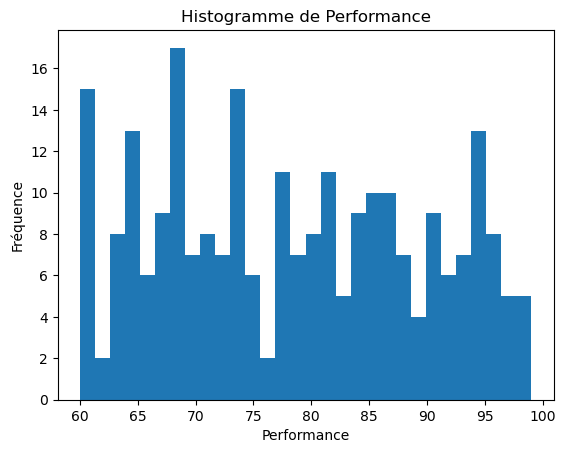

In [23]:
plt.figure()
plt.hist(serie,bins = 30) # 30 c'set le nombre de classes
plt.title(f"Histogramme de {variable}")
plt.xlabel(variable)
plt.ylabel("Fréquence") # nombre d'observation dans la classe
plt.show()

In [24]:
# Densité(KDE) si seaborn est disponible

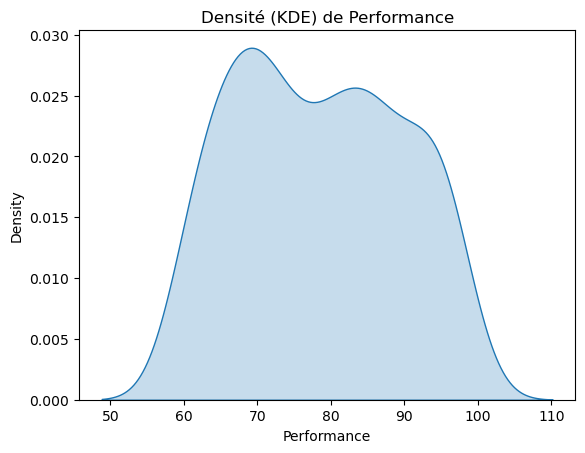

In [25]:
if sns is not None:
    plt.figure()
    sns.kdeplot(serie,fill = True)
    plt.title(f"Densité (KDE) de {variable}")
    plt.xlabel(variable)
    plt.show()
else:
    print("Seaborn n'est pas installé, KDE non tracé.")

In [26]:
# Boxplot

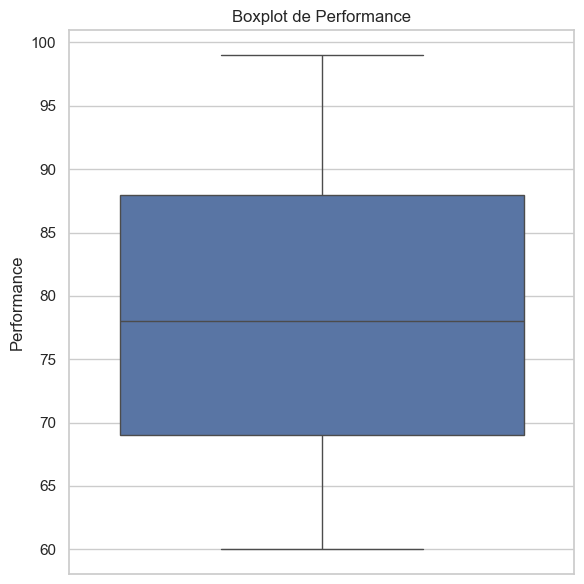

In [27]:
sns.set_theme(style = "whitegrid")
plt.figure(figsize = (6,6))
sns.boxplot(y = serie, color = "#4C72B0")
plt.title(f"Boxplot de {variable}")
plt.ylabel(variable)
plt.tight_layout()
plt.show()

In [28]:
# variable qualitatives

In [29]:
var_quali = "Niveau_Etude"
serie_quali = df[var_quali] #.astype("catégory")
serie_quali.head()

ID
1      Master
2    Doctorat
3         Bac
4      Master
5      Master
Name: Niveau_Etude, dtype: object

In [30]:
# effectifs et proportion

In [31]:
effectifs = serie_quali.value_counts()
effectifs

Niveau_Etude
Master      108
Licence      83
Bac          35
Doctorat     24
Name: count, dtype: int64

In [32]:
proportions = serie_quali.value_counts(normalize = True)*100
proportions.round(2)

Niveau_Etude
Master      43.2
Licence     33.2
Bac         14.0
Doctorat     9.6
Name: proportion, dtype: float64

In [33]:
# Les graphiques

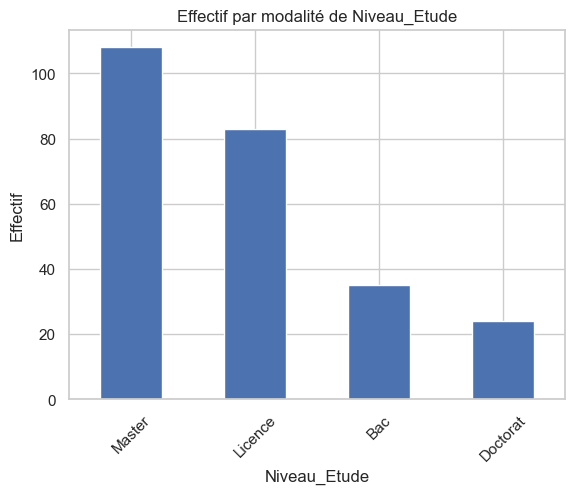

In [34]:
plt.figure()
effectifs.plot(kind = "bar")
plt.title(f"Effectif par modalité de {var_quali}")
plt.xlabel(var_quali)
plt.ylabel("Effectif")
plt.xticks(rotation = 45)
plt.show()

In [35]:
# Diagramme circulaire pour les proportions

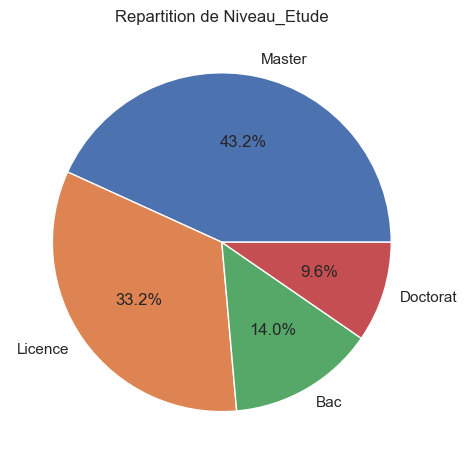

In [36]:
plt.figure()
proportions.plot(kind = "pie",autopct = "%1.1f%%")
plt.title(f"Repartition de {var_quali}")
plt.ylabel("") # on enlève le label par défaut
plt.tight_layout()
plt.show()

In [37]:
# Sauvegarde de df au format csv
df.to_csv("data_preprocessed.csv")

In [38]:
df = pd.read_csv("data_preprocessed.csv",index_col = 0)
df.head()

,Nom,Pays,Departement,Poste,Sexe,Age,Anciennete,Niveau_Etude,Performance,Salaire
ID,,,,,,,,,,
1,Employé_001,Tchad,Comptabilité,Technicien,H,26,12,Master,64,1608285
2,Employé_002,RCA,Opérations,Directeur,H,44,1,Doctorat,60,3038856
3,Employé_003,Congo,Comptabilité,Technicien,H,25,4,Bac,99,807421
4,Employé_004,RCA,Opérations,Conseiller,H,33,10,Master,71,1567727
5,Employé_005,RCA,Crédit,Conseiller,F,41,5,Master,95,1412418


In [39]:
# Pour compter les nombres de valeurs manquantes
df.isna().sum()

Nom             0
Pays            0
Departement     0
Poste           0
Sexe            0
Age             0
Anciennete      0
Niveau_Etude    0
Performance     0
Salaire         0
dtype: int64

# Pour détecter les valeurs extrêmes par la graphique

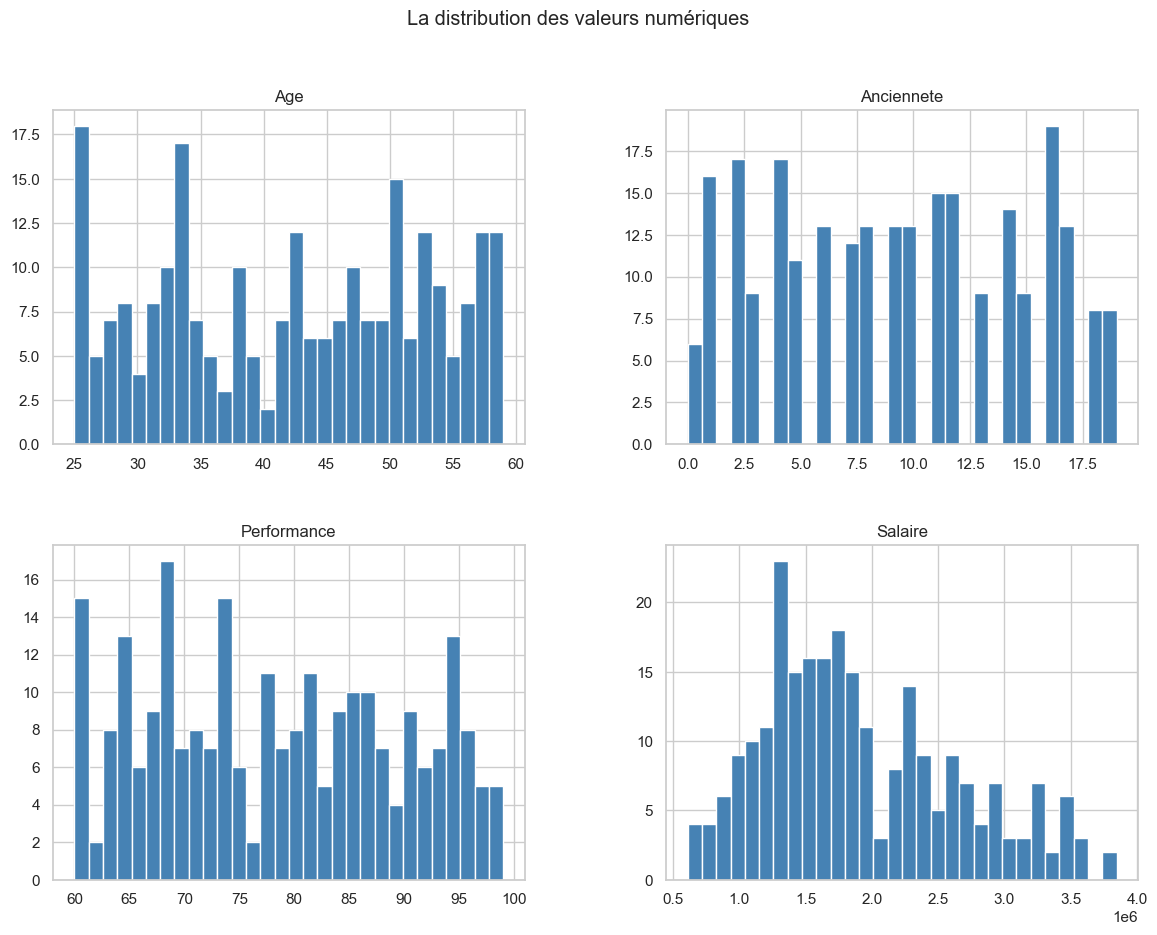

In [40]:
df.select_dtypes(include = "number").hist(figsize = (14,10), bins = 30, color = "steelblue",edgecolor = "white")
plt.suptitle("La distribution des valeurs numériques")
plt.show()

# On peut voir avec boite à moustache

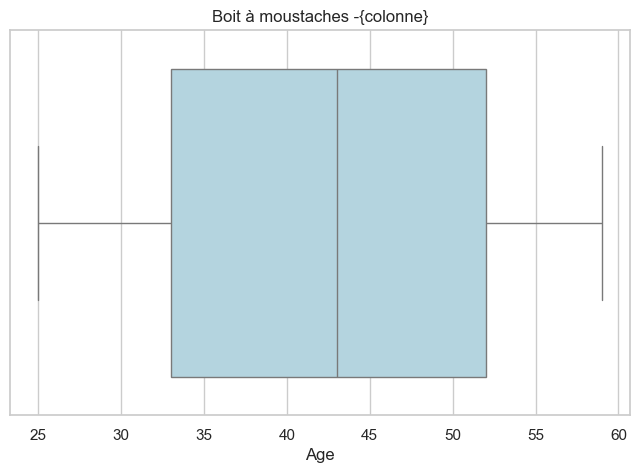

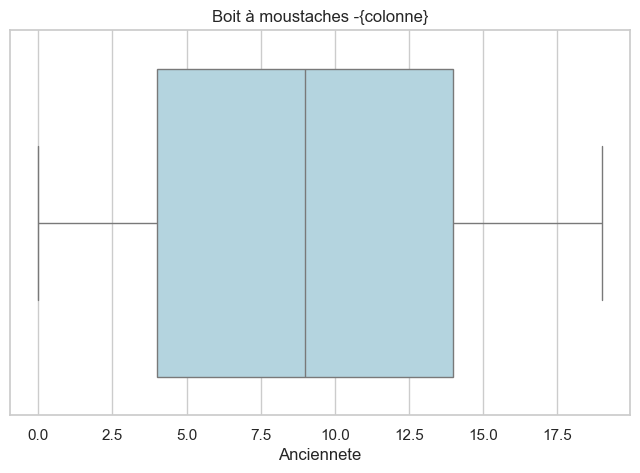

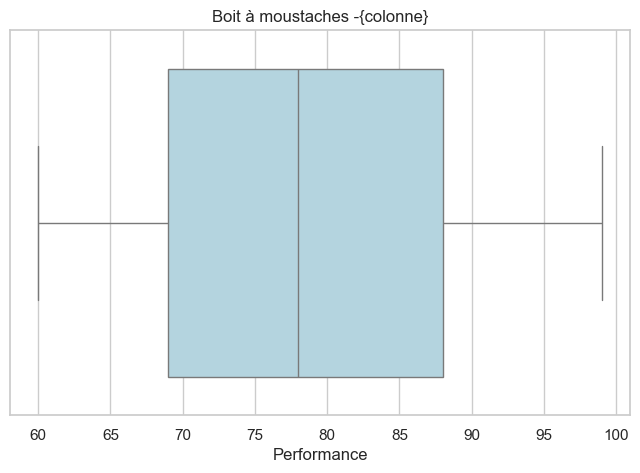

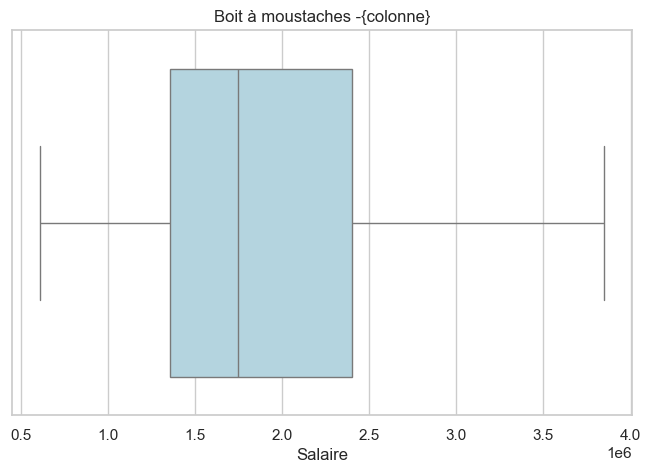

In [41]:
colonnes_numeriques = df.select_dtypes(include = ["int64","float64"]).columns
for colonne in colonnes_numeriques:
    plt.figure(figsize = (8,5))
    sns.boxplot(x = df[colonne], color = "lightblue")
    plt.title("Boit à moustaches -{colonne}")
    plt.xlabel(colonne)
    plt.show()

# Aléatoire simple

In [42]:
sample_simple = df.sample(n = 20, random_state = 42)
sample_simple

,Nom,Pays,Departement,Poste,Sexe,Age,Anciennete,Niveau_Etude,Performance,Salaire
ID,,,,,,,,,,
143,Employé_143,Tchad,IT,Manager,H,52,2,Bac,62,1820609
7,Employé_007,Congo,Service Client,Technicien,H,35,9,Master,90,1365108
98,Employé_098,RCA,Conformité,Directeur,F,49,12,Master,84,3446133
61,Employé_061,Tchad,Direction,Assistant,F,57,16,Master,67,1545673
113,Employé_113,Congo,IT,Conseiller,H,45,17,Licence,72,1788067
182,Employé_182,Cameroun,Conformité,Manager,H,47,10,Bac,67,2235262
198,Employé_198,Tchad,Conformité,Assistant,H,59,10,Master,72,1340546
185,Employé_185,Cameroun,Service Client,Analyste,H,31,13,Master,89,2149340
10,Employé_010,RCA,Conformité,Technicien,H,59,5,Master,62,1263189


# Stratifie

In [43]:
sample_stratifie = df.groupby("Departement").sample(n = 5, random_state = 42)
sample_stratifie

,Nom,Pays,Departement,Poste,Sexe,Age,Anciennete,Niveau_Etude,Performance,Salaire
ID,,,,,,,,,,
226,Employé_226,Guinée Équatoriale,Comptabilité,Analyste,H,47,1,Licence,95,1321229
96,Employé_096,Tchad,Comptabilité,Analyste,H,37,14,Licence,68,1976559
161,Employé_161,Gabon,Comptabilité,Directeur,H,53,4,Master,65,2964099
126,Employé_126,Tchad,Comptabilité,Assistant,H,35,2,Licence,74,698864
44,Employé_044,Congo,Comptabilité,Technicien,F,57,0,Licence,96,835327
139,Employé_139,Congo,Conformité,Technicien,H,57,12,Doctorat,73,1712020
103,Employé_103,Cameroun,Conformité,Technicien,F,32,16,Licence,70,1619264
168,Employé_168,Tchad,Conformité,Analyste,F,26,3,Master,70,1601268
80,Employé_080,Gabon,Conformité,Conseiller,F,36,16,Master,71,1922982


# Par proportion

# Par proportion

In [44]:
n = 200
proportions = df["Departement"].value_counts(normalize = True)
n_par_departement = (proportions*n).round().astype(int)
print(proportions)
print(n_par_departement)

Departement
Conformité        0.172
Direction         0.144
IT                0.132
Comptabilité      0.128
Opérations        0.128
Crédit            0.112
Service Client    0.104
RH                0.080
Name: proportion, dtype: float64
Departement
Conformité        34
Direction         29
IT                26
Comptabilité      26
Opérations        26
Crédit            22
Service Client    21
RH                16
Name: proportion, dtype: int64


In [46]:
#  Colonnes sans la colonne de groupement
group_col = "Departement"
other_cols = [c for c in df.columns if c!= group_col ]
# Echantillonnage manuel propre (sans wiarning)
sample_manuel = (
               df.groupby(group_col)[other_cols].apply(lambda g:g.sample(n = n_par_departement.loc[g.name],random_state = 42 )).reset_index(level = 0).reset_index(drop = True)
    
)
# Répartition dans l'échantillon
sample_manuel["Departement"].value_counts(normalize = True)

Departement
Conformité        0.170
Direction         0.145
Comptabilité      0.130
IT                0.130
Opérations        0.130
Crédit            0.110
Service Client    0.105
RH                0.080
Name: proportion, dtype: float64

In [47]:
print("Taille population :",len(df))
print(df["Departement"].value_counts(normalize = True))
print("\nTaille échantillon :",len(sample_manuel))
print(sample_manuel["Departement"].value_counts(normalize = True))

Taille population : 250
Departement
Conformité        0.172
Direction         0.144
IT                0.132
Comptabilité      0.128
Opérations        0.128
Crédit            0.112
Service Client    0.104
RH                0.080
Name: proportion, dtype: float64

Taille échantillon : 200
Departement
Conformité        0.170
Direction         0.145
Comptabilité      0.130
IT                0.130
Opérations        0.130
Crédit            0.110
Service Client    0.105
RH                0.080
Name: proportion, dtype: float64


# Statistiques bivariées

In [48]:
# Variables quanttitatives
x = df["Anciennete"]
y = df["Salaire"]

In [49]:
x

ID
1      12
2       1
3       4
4      10
5       5
       ..
246    17
247     5
248     4
249    15
250    12
Name: Anciennete, Length: 250, dtype: int64

In [50]:
y

ID
1      1608285
2      3038856
3       807421
4      1567727
5      1412418
        ...   
246    1356297
247    1736614
248     960428
249    1603812
250    2609353
Name: Salaire, Length: 250, dtype: int64

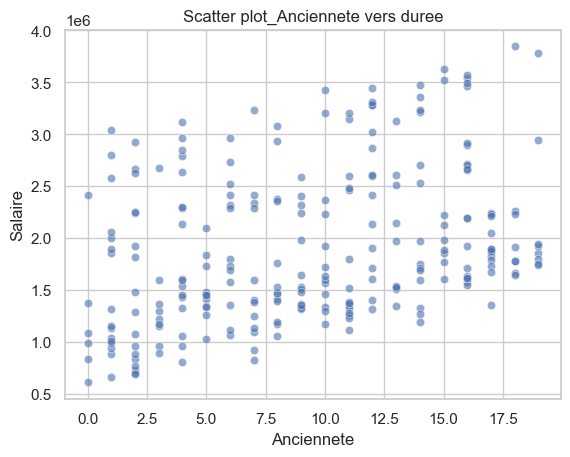

In [51]:
# Graphique
plt.figure()
if sns: sns.scatterplot(x=x,y=y, alpha = 0.6) 
else: plt.scatter(x,y, alpha = 0.6)
plt.xlabel("Anciennete")
plt.ylabel("Salaire")
plt.title("Scatter plot_Anciennete vers duree")
plt.show()

# Pearson est élevée(0.70) alors elle est forte et positive, sinon forte et négative

# Comment interpréter la force d'une corrélation?
# 0.00 - O.19, c'est très faible
# 0.20 - O.39, c'est faible
# 0.40 - O.59, c'est modérée
# 0.60 - O.79, c'est forte
# 0.80 - 1.00, c'est très forte

In [54]:
# Covariance
cov_xy = np.cov(x,y,ddof = 1)[0,1]
# Corrélation de pearson
pearson_r,pearson_p = stats.pearsonr(x,y)
# corrélation de spearman
spearman_rho,spearman_p = stats.spearmanr(x,y)
# corrélation de kendall
kendall_tau,kendall_p = stats.kendalltau(x,y)

print("Covariance :",cov_xy)
print(f"Corrélation de pearson :r = {pearson_r:.3f}(p = {pearson_p:.3e})")
print(f"Corrélation de spearman :Р = {spearman_rho:.3f}(p = {spearman_p:.3e})")
print(f"Corrélation de kendall : τ = {kendall_tau:.3f}(p = {kendall_p:.3e})")

Covariance : 1433925.93113253
Corrélation de pearson :r = 0.352(p = 1.043e-08)
Corrélation de spearman :Р = 0.382(p = 4.082e-10)
Corrélation de kendall : τ = 0.276(p = 2.078e-10)


In [61]:
# La relation entre une variable qualitative te quantigtative
var_quali = "Sexe"
var_quanti = "Anciennete"
df[[var_quali,var_quanti]].groupby(var_quali).describe().T

Sexe                      F           H
Anciennete count  90.000000  160.000000
           mean    9.211111    9.362500
           std     5.621976    5.520103
           min     0.000000    0.000000
           25%     5.000000    4.000000
           50%     9.500000    9.000000
           75%    14.000000   14.000000
           max    19.000000   19.000000

Text(0.5, 1.0, 'Boxplot_Anciennete par Sexe')

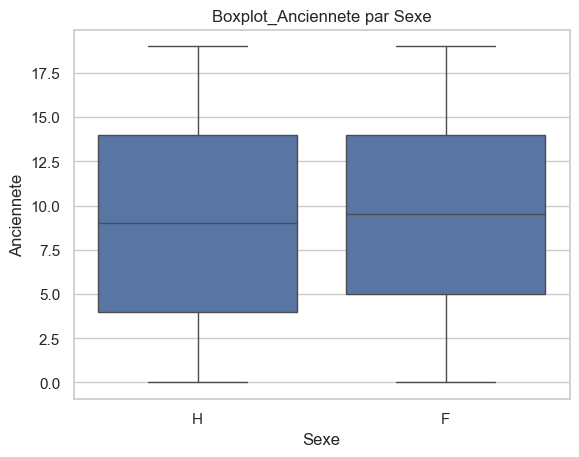

In [60]:
sns.boxplot(x = "Sexe",y = "Anciennete", data = df) # La relation entre une variable qualitative te quantigtative
plt.title("Boxplot_Anciennete par Sexe")

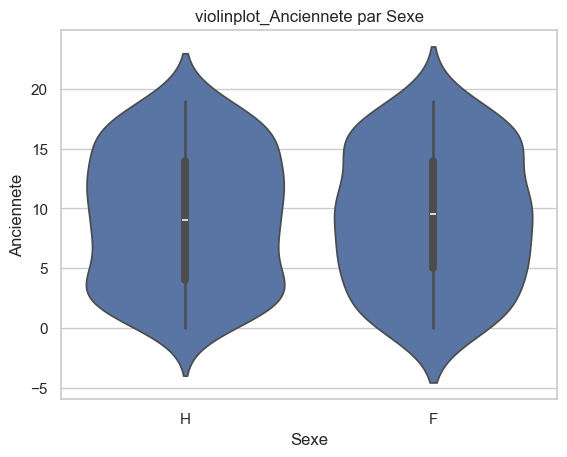

In [62]:
plt.figure()
sns.violinplot(x = "Sexe",y = "Anciennete", data = df)
plt.title("violinplot_Anciennete par Sexe")
plt.show()

In [64]:
# Pour savoir qui Anciennete plus ou moins
df.groupby("Sexe")["Anciennete"].agg(
   moyenne = "mean",
   mediane = "median",
   variance = "var",
   ecart_type = "std",
   minimum = "min",
   Q1 = lambda x: x.quantile(0.25),
   Q2 = "median",
   Q3 = lambda x: x.quantile(0.75),
   maximum = "max",
   IQR = lambda x: x.quantile(0.75)-x.quantile(0.25),
   etendue = lambda x: x.max()-x.min()
)

,moyenne,mediane,variance,ecart_type,minimum,Q1,Q2,Q3,maximum,IQR,etendue
Sexe,,,,,,,,,,,
F,9.211111,9.5,31.606617,5.621976,0,5.0,9.5,14.0,19,9.0,19
H,9.362500,9.0,30.471541,5.520103,0,4.0,9.0,14.0,19,10.0,19


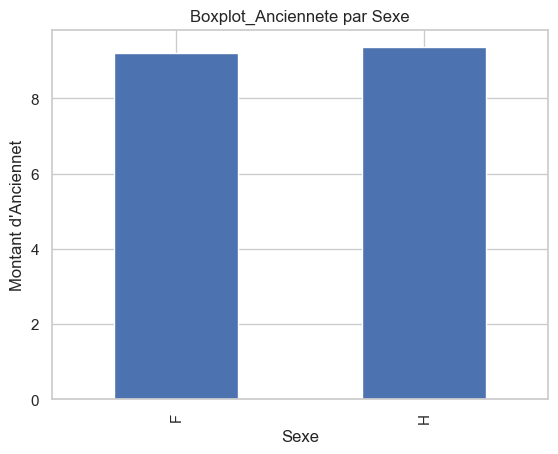

In [65]:
means = df.groupby("Sexe")["Anciennete"].mean()
plt.figure()
means.plot(kind = "bar")
plt.ylabel("Montant d'Anciennet")
plt.title("Boxplot_Anciennete par Sexe")
plt.show()

# On va faire une analyse de données entre les variables qualitattives avec indicateurs table de contingence et graphique countplot, heatmp.


In [56]:
table = pd.crosstab(df["Sexe"],df["Niveau_Etude"])
table

Niveau_Etude,Bac,Doctorat,Licence,Master
Sexe,,,,
F,12,11,26,41
H,23,13,57,67


In [58]:
# Pour mieux comprendre, on passe par proportion
table_propo = table.div(table.sum(axis = 1),axis = 0)*100
table_propo

Niveau_Etude,Bac,Doctorat,Licence,Master
Sexe,,,,
F,13.333333,12.222222,28.888889,45.555556
H,14.375000,8.125000,35.625000,41.875000


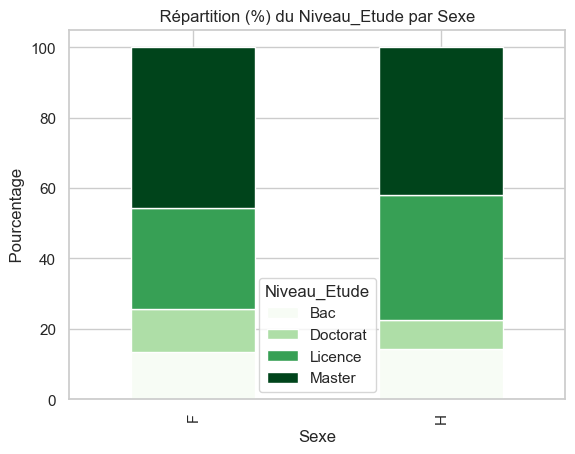

In [59]:
# Graphique
table_propo.plot(kind = "bar",stacked = True, colormap = "Greens")
plt.title(" Répartition (%) du Niveau_Etude par Sexe ")
plt.ylabel(" Pourcentage ")
plt.show()

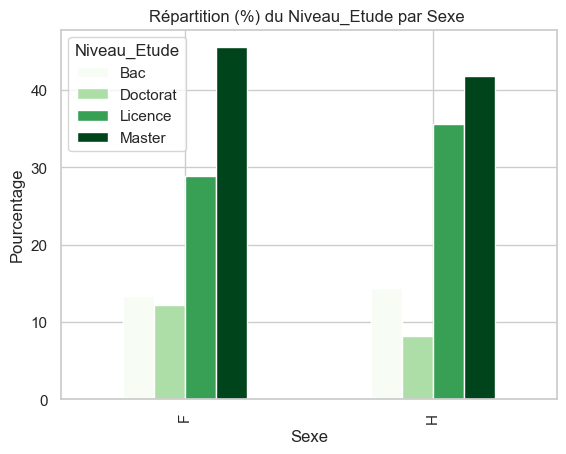

In [66]:
# Graphique avec False
table_propo.plot(kind = "bar",stacked = False, colormap = "Greens")
plt.title("Répartition (%) du Niveau_Etude par Sexe ")
plt.ylabel("Pourcentage")
plt.show()

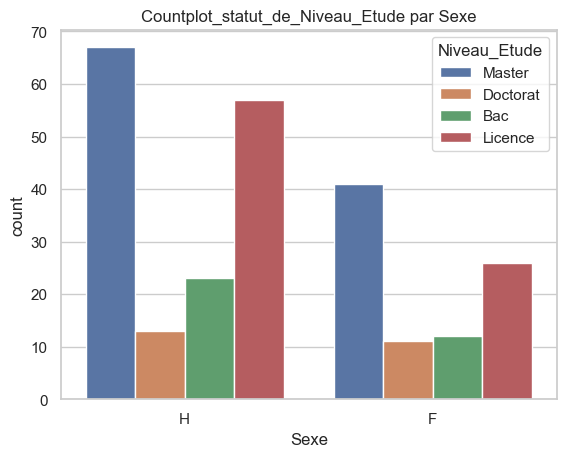

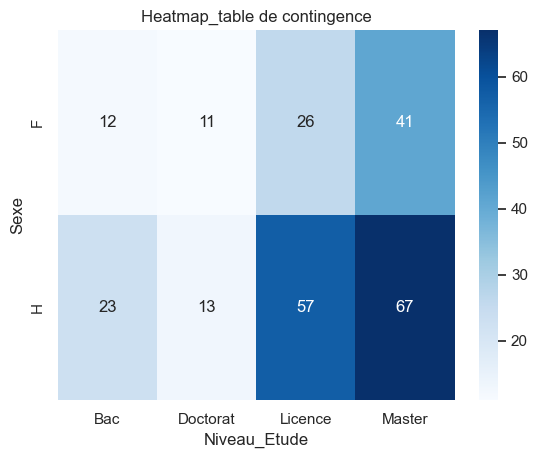

In [67]:
plt.figure()
sns.countplot(x = "Sexe",hue = "Niveau_Etude", data = df)
plt.title("Countplot_statut_de_Niveau_Etude par Sexe")
plt.show()

plt.figure()
sns.heatmap(table, annot = True, fmt = "d",cmap = "Blues")
plt.title("Heatmap_table de contingence")
plt.show()

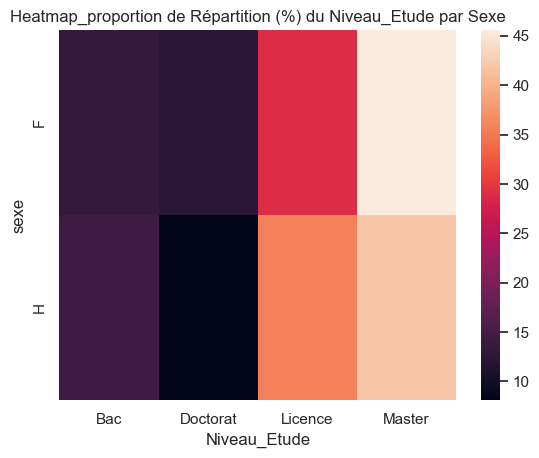

In [68]:
plt.figure()
sns.heatmap(table_propo, annot = False, fmt = ".1f")
plt.title("Heatmap_proportion de Répartition (%) du Niveau_Etude par Sexe")
plt.ylabel("sexe")
plt.xlabel("Niveau_Etude")
plt.show()

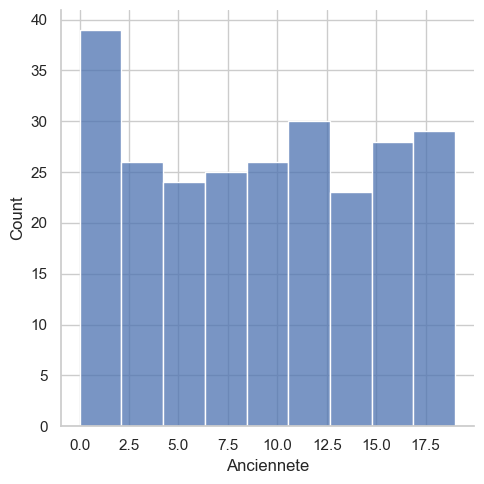

In [69]:
sns.displot(df.Anciennete)

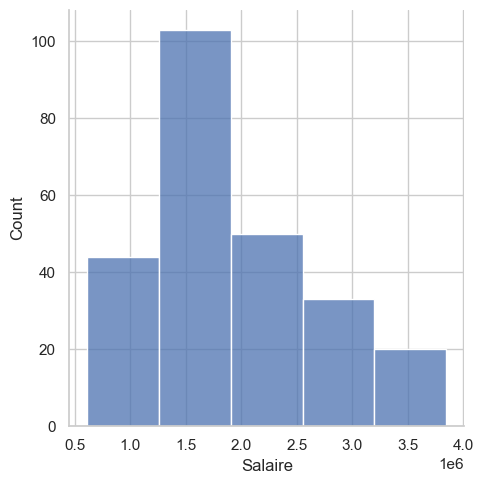

In [72]:
sns.displot(df.Salaire, bins = 5, kde = False) # Avec l'estimation de la distrubition

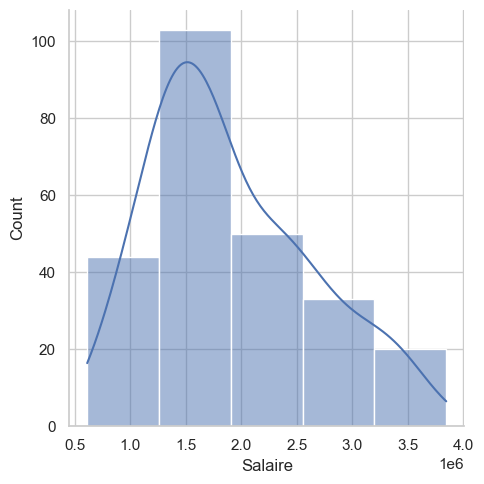

In [73]:
sns.displot(df.Salaire, bins = 5, kde = True) # Avec l'estimation de la distrubition

<Axes: ylabel='Anciennete'>

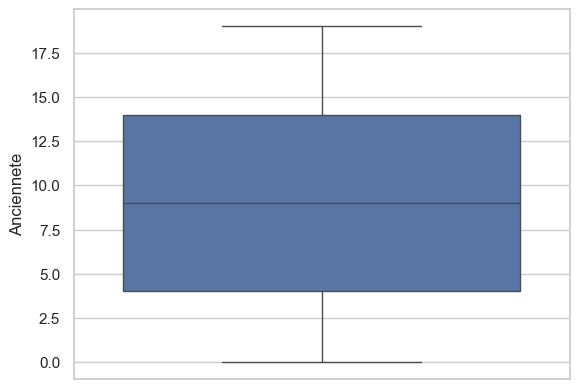

In [74]:
sns.boxplot( y = "Anciennete",data = df) # Pour avoir une boite à moutache

<Axes: ylabel='Anciennete'>

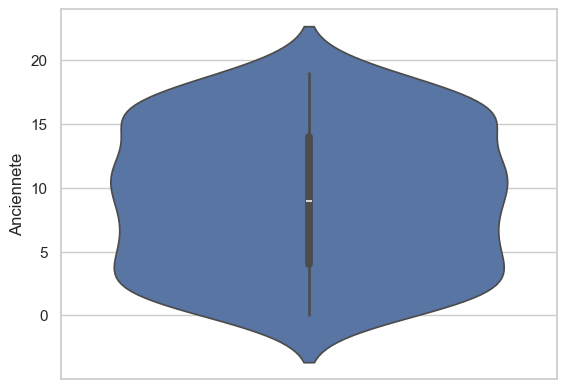

In [75]:
sns.violinplot(y = "Anciennete",data = df)

<Axes: ylabel='Anciennete'>

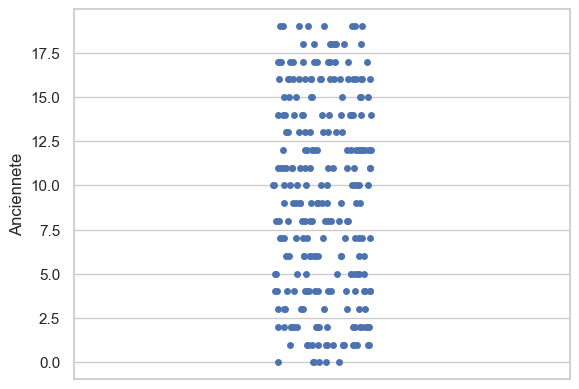

In [76]:
sns.stripplot(y = "Anciennete", data = df)# Nuage

<Axes: ylabel='Anciennete'>

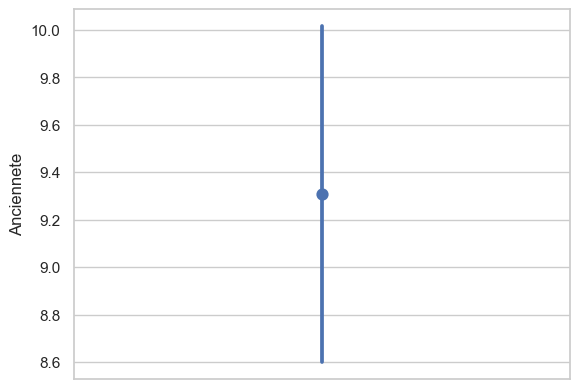

In [77]:
sns.pointplot(y = "Anciennete", data = df) #Pour avoir la moyenne

<Axes: xlabel='Sexe', ylabel='Niveau_Etude'>

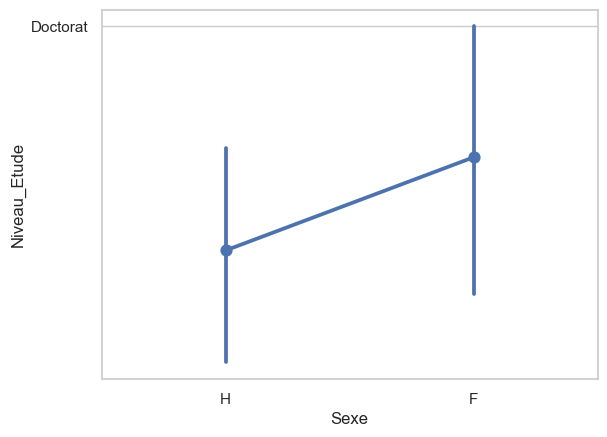

In [79]:
sns.pointplot(x = "Sexe", y = "Niveau_Etude", data = df) # Pour voir la moyenne de deux variables

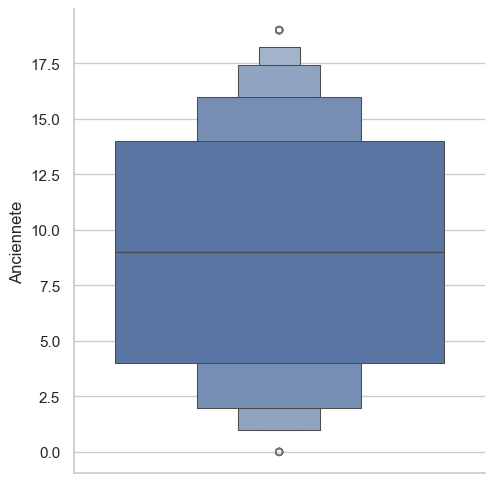

In [84]:
sns.catplot(y = "Anciennete", data = df, kind = "boxen")